# Spark Basics

## DataFrames, RDDs & Partitions

This notebook introduces core Apache Spark concepts

**Topics covered:**
1. SparkSession — the entry point
2. Reading CSV data into a DataFrame
3. DataFrame inspection — schema, columns, show, describe
4. The RDD behind a DataFrame
5. Partitions — how data is distributed
6. Transformations vs Actions
7. Lazy evaluation

Dataset: `food-inspections/` — Chicago food inspections, split into 33 CSV files (under 10 MB each) (local, same folder as this notebook)

## 1. SparkSession

The **SparkSession** is the single entry point to all Spark functionality. It wraps the older `SparkContext`, `SQLContext`, and `HiveContext`.

```
SparkSession
    └── SparkContext        ← manages the cluster connection
          └── RDD API       ← low-level distributed collection
    └── SQL / DataFrame API ← high-level structured API
```

`getOrCreate()` reuses an existing session if one already exists in the JVM, which is useful in notebooks.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col

spark = SparkSession.builder \
    .appName('SparkBasics') \
    .getOrCreate()

# The underlying SparkContext
sc = spark.sparkContext
print("Spark version :", spark.version)
print("App name      :", sc.appName)
print("Master        :", sc.master)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/16 17:13:27 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version : 4.3.0
App name      : SparkBasics
Master        : local[*]


## 2. Reading CSV Data into a DataFrame

A **DataFrame** is a distributed collection of rows organised into named columns — conceptually identical to a Pandas DataFrame, but the data is spread across a cluster.

Key read options:
| Option | Meaning |
|--------|--------|
| `header=True` | First row is the column header |
| `inferSchema=True` | Spark samples the data to guess column types (one extra pass over the file) |
| `sep` | Delimiter (default `,`) |

In [2]:
import re

inspections = spark.read.csv(
    "food-inspections/*.csv",   # split files, each with its own header
    inferSchema=True,
    header=True,
    multiLine=True,   # Violations text can contain embedded newlines
    escape='"'
)

# Normalise headers to snake_case ("Inspection ID" -> "inspection_id", "License #" -> "license")
inspections = inspections.toDF(*[re.sub(r'_+$', '', re.sub(r'\W+', '_', c.strip())).lower()
                                 for c in inspections.columns])

print("inspections rows :", inspections.count())

inspections rows : 277636


## 3. DataFrame Inspection

### 3.1 Schema

The **schema** describes column names and their data types. Spark uses its own type system (`IntegerType`, `StringType`, `DoubleType`, …).

In [3]:
# Tree-formatted schema
print("=== inspections schema ===")
inspections.printSchema()

=== inspections schema ===
root
 |-- inspection_id: integer (nullable = true)
 |-- dba_name: string (nullable = true)
 |-- aka_name: string (nullable = true)
 |-- license: integer (nullable = true)
 |-- facility_type: string (nullable = true)
 |-- risk: string (nullable = true)
 |-- address: string (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- zip: integer (nullable = true)
 |-- inspection_date: string (nullable = true)
 |-- inspection_type: string (nullable = true)
 |-- results: string (nullable = true)
 |-- violations: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- location: string (nullable = true)



### 3.2 Column names & types as a list

In [4]:
print("inspections columns :", inspections.columns)
print()
# dtypes returns a list of (name, type_string) tuples
print("inspections dtypes  :")
for name, dtype in inspections.dtypes:
    print(f"  {name:20s} -> {dtype}")

inspections columns : ['inspection_id', 'dba_name', 'aka_name', 'license', 'facility_type', 'risk', 'address', 'city', 'state', 'zip', 'inspection_date', 'inspection_type', 'results', 'violations', 'latitude', 'longitude', 'location']

inspections dtypes  :
  inspection_id        -> int
  dba_name             -> string
  aka_name             -> string
  license              -> int
  facility_type        -> string
  risk                 -> string
  address              -> string
  city                 -> string
  state                -> string
  zip                  -> int
  inspection_date      -> string
  inspection_type      -> string
  results              -> string
  violations           -> string
  latitude             -> double
  longitude            -> double
  location             -> string


### 3.3 Viewing rows

In [5]:
# show() is an ACTION — it triggers computation and prints to stdout
# truncate=False prevents long strings from being cut off
(inspections
    .select('inspection_id', 'dba_name', 'facility_type', 'risk', 'inspection_date', 'results')
    .show(5, truncate=False))

+-------------+----------------------------+----------------------------+---------------+---------------+---------------+
|inspection_id|dba_name                    |facility_type               |risk           |inspection_date|results        |
+-------------+----------------------------+----------------------------+---------------+---------------+---------------+
|2600644      |LOS PANCHO'S RESTAURANT     |Restaurant                  |Risk 1 (High)  |08/23/2024     |No Entry       |
|2600630      |ELEVEN ELEVEN               |Restaurant                  |Risk 1 (High)  |08/23/2024     |Out of Business|
|2600617      |HOWARD AREA COMMUNITY CENTER|Children's Services Facility|Risk 1 (High)  |08/23/2024     |Fail           |
|2600584      |CRAVE COOKIES               |Restaurant                  |Risk 2 (Medium)|08/23/2024     |Pass           |
|2600575      |GOBLINBAT INC.              |Restaurant                  |Risk 2 (Medium)|08/23/2024     |Pass           |
+-------------+---------

In [6]:
# head() / take() return Python Row objects (driver-side)
first_row = inspections.head(1)[0]
print("Row type        :", type(first_row))
print("inspection_id   :", first_row['inspection_id'])
print("dba_name        :", first_row['dba_name'])
print("results         :", first_row['results'])

Row type        : <class 'pyspark.sql.types.Row'>
inspection_id   : 2600644
dba_name        : LOS PANCHO'S RESTAURANT
results         : No Entry


### 3.4 Summary statistics

In [7]:
# describe() computes count, mean, stddev, min, max for the chosen columns
inspections.describe('latitude', 'longitude').show()

+-------+-------------------+-------------------+
|summary|           latitude|          longitude|
+-------+-------------------+-------------------+
|  count|             276678|             276678|
|   mean|  41.88070915179387| -87.67629957142523|
| stddev|0.08100548655533849|0.05841573001954283|
|    min|  41.64467013219805| -87.90687413400109|
|    max|  42.02106424782547|  -87.5250941359867|
+-------+-------------------+-------------------+



## 4. The RDD Behind a DataFrame

Every DataFrame is backed by an **RDD** (Resilient Distributed Dataset) — Spark's fundamental low-level abstraction.

| | RDD | DataFrame |
|--|-----|-----------|
| API level | Low-level | High-level (SQL-like) |
| Type safety | Yes (generic) | Schema-based |
| Optimisation | Manual | Catalyst optimizer |
| Serialisation | Java / Kryo | Tungsten binary |

You can access the underlying RDD via `.rdd`. Each element becomes a `Row` object.

In [8]:
# Access the underlying RDD
rdd = inspections.rdd
print("RDD type          :", type(rdd))

# first() is an action — returns the first Row
first = rdd.first()
print("First RDD element :", first)
print("Element type      :", type(first))

RDD type          : <class 'pyspark.core.rdd.RDD'>
First RDD element : Row(inspection_id=2600644, dba_name="LOS PANCHO'S RESTAURANT", aka_name="LOS PANCHO'S RESTAURANT", license=37209, facility_type='Restaurant', risk='Risk 1 (High)', address='4139 W 63RD ST ', city='CHICAGO', state='IL', zip=60629, inspection_date='08/23/2024', inspection_type='Non-Inspection', results='No Entry', violations=None, latitude=41.77849967060516, longitude=-87.72673558708598, location='(41.77849967060516, -87.72673558708598)')
Element type      : <class 'pyspark.sql.types.Row'>


In [9]:
# map() is a TRANSFORMATION — returns a new RDD without executing yet
# Extract (facility_type, results) tuples
type_result_rdd = rdd.map(lambda row: (row['facility_type'], row['results']))

# take() is an ACTION — triggers the computation
print("Sample (facility_type, results) pairs:")
for pair in type_result_rdd.take(5):
    print(" ", pair)

Sample (facility_type, results) pairs:
  ('Restaurant', 'No Entry')
  ('Restaurant', 'Out of Business')
  ("Children's Services Facility", 'Fail')
  ('Restaurant', 'Pass')
  ('Restaurant', 'Pass')


In [10]:
# reduceByKey is a TRANSFORMATION that groups by key and aggregates
# count inspections per facility type
type_count_rdd = type_result_rdd.map(lambda x: (x[0], 1)).reduceByKey(lambda a, b: a + b)

# sortBy is also a transformation; take() is an action
top_types = type_count_rdd.sortBy(lambda x: -x[1]).take(5)
print("Top 5 facility types (facility_type, #inspections):")
for t in top_types:
    print(" ", t)

[Stage 12:>                                                         (0 + 1) / 1]

Top 5 facility types (facility_type, #inspections):
  ('Restaurant', 187146)
  ('Grocery Store', 34220)
  ('School', 17389)
  ("Children's Services Facility", 6101)
  (None, 5158)


## 5. Partitions

Spark splits data into **partitions** — logical chunks that can be processed in parallel across executor cores.

```
DataFrame  →  [ partition 0 | partition 1 | partition 2 | ... ]
                     ↓               ↓               ↓
               executor core   executor core   executor core
```

**Rules of thumb:**
- Default: 1 partition per HDFS/S3 block (128 MB) or per CPU core for local mode
- `spark.default.parallelism` controls shuffle partitions (default **200** for SQL)
- Too few → under-utilised cores; too many → scheduling overhead

In [11]:
def displaypartitions(df):
    """Print partition count and a row-count breakdown per partition."""
    num = df.rdd.getNumPartitions()
    print(f"Number of partitions: {num}")
    (df.withColumn("partitionId", F.spark_partition_id())
       .groupBy("partitionId")
       .count()
       .orderBy(F.asc("partitionId"))
       .show(num))

print("Default parallelism (local cores) :", sc.defaultParallelism)
print("Default shuffle partitions (SQL)  :", spark.conf.get("spark.sql.shuffle.partitions"))
print()
print("=== inspections ===")
displaypartitions(inspections)

Default parallelism (local cores) : 12
Default shuffle partitions (SQL)  : 200

=== inspections ===
Number of partitions: 1
+-----------+------+
|partitionId| count|
+-----------+------+
|          0|277636|
+-----------+------+



In [12]:
# repartition() — exact target count, causes a full shuffle
inspections_4 = inspections.repartition(4)
print("After repartition(4):")
displaypartitions(inspections_4)

# coalesce() — reduces partitions WITHOUT a full shuffle (cheaper for shrinking)
inspections_2 = inspections_4.coalesce(2)
print("After coalesce(2):")
displaypartitions(inspections_2)

After repartition(4):


[Stage 17:>                                                         (0 + 1) / 1]

Number of partitions: 4


+-----------+-----+
|partitionId|count|
+-----------+-----+
|          0|69409|
|          1|69409|
|          2|69409|
|          3|69409|
+-----------+-----+

After coalesce(2):


[Stage 24:>                                                         (0 + 1) / 1]

Number of partitions: 2
+-----------+------+
|partitionId| count|
+-----------+------+
|          0|138818|
|          1|138818|
+-----------+------+



In [13]:
# Column-based repartitioning — Spark hashes the column value to assign partitions,
# ensuring all rows with the same risk land in the same partition (useful before joins/groupBy)
by_risk = inspections.repartition(F.col("risk"))
print("Repartitioned by risk:")
displaypartitions(by_risk)

# Multiple columns — partition key is the combined hash of both columns
by_risk_results = inspections.repartition(F.col("risk"), F.col("results"))
print("Repartitioned by risk + results:")
displaypartitions(by_risk_results)

Repartitioned by risk:


[Stage 31:>                                                         (0 + 1) / 1]

Number of partitions: 3


+-----------+------+
|partitionId| count|
+-----------+------+
|          0|277636|
+-----------+------+

Repartitioned by risk + results:


[Stage 38:>                                                         (0 + 1) / 1]

Number of partitions: 7
+-----------+------+
|partitionId| count|
+-----------+------+
|          0|277636|
+-----------+------+



### 5.1 Visualising partitions

Bar charts of **rows per partition** make skew obvious: even bars = balanced work, one tall bar = one straggler task.

**Note:** `repartition(risk)` shows one partition because Spark's Adaptive Query Execution (AQE) merges the small shuffle output into a single partition. Set `spark.sql.adaptive.enabled` to `false` to see the raw hash split.

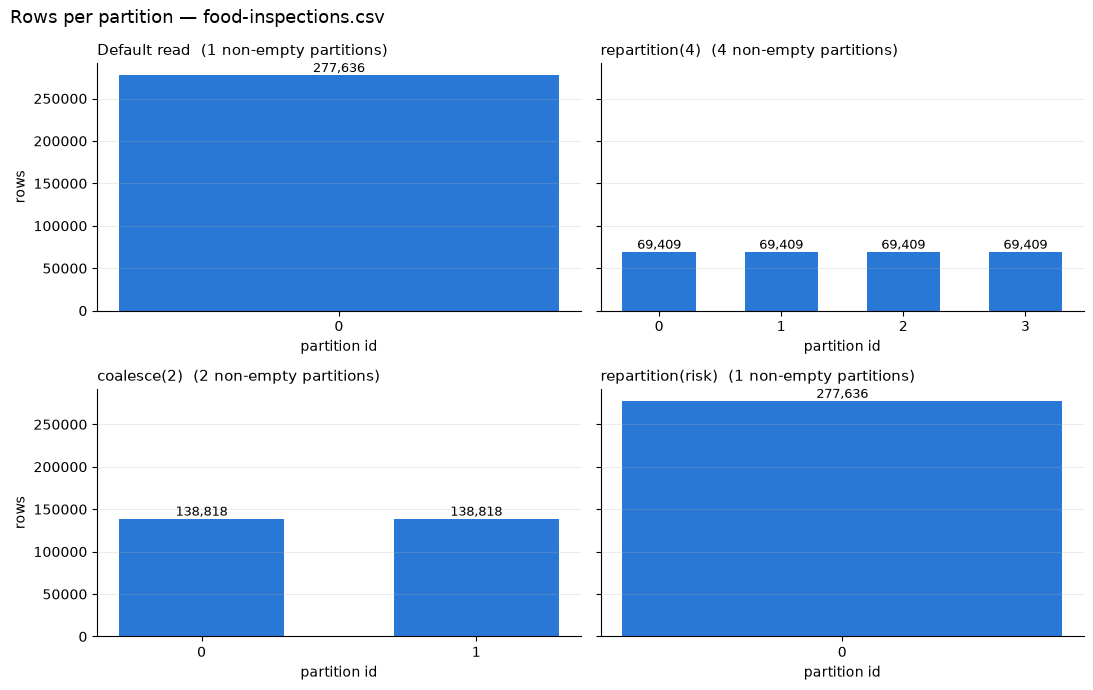

In [14]:
import matplotlib.pyplot as plt

def partition_counts(df):
    """Return (partition ids, row counts) collected to the driver."""
    rows = (df.withColumn("partitionId", F.spark_partition_id())
              .groupBy("partitionId").count()
              .orderBy("partitionId").collect())
    return [r["partitionId"] for r in rows], [r["count"] for r in rows]

layouts = [
    ("Default read",            inspections),
    ("repartition(4)",          inspections_4),
    ("coalesce(2)",             inspections_2),
    ("repartition(risk)",       by_risk),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, (title, df) in zip(axes.flat, layouts):
    ids, counts = partition_counts(df)
    # Many empty/near-empty partitions (hash on few keys) -> keep non-empty ones only
    pairs = [(i, c) for i, c in zip(ids, counts) if c > 0]
    xs = [str(i) for i, _ in pairs]
    ys = [c for _, c in pairs]
    ax.bar(xs, ys, color="#2a78d6", width=0.6)
    ax.set_title(f"{title}  ({len(ys)} non-empty partitions)", loc="left", fontsize=11)
    ax.set_xlabel("partition id")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    if len(ys) <= 8:
        for x, y in zip(xs, ys):
            ax.text(x, y, f"{y:,}", ha="center", va="bottom", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("rows")
fig.suptitle("Rows per partition — food-inspections", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

## 6. Transformations vs Actions

Spark operations fall into two categories:

| | Transformation | Action |
|--|---------------|--------|
| Returns | New DataFrame / RDD | Result to driver / side-effect |
| Execution | **Lazy** — builds a plan | **Eager** — triggers computation |
| Examples | `select`, `filter`, `groupBy`, `join`, `map` | `show`, `count`, `collect`, `take`, `write` |

### Narrow vs Wide Transformations

| Type | Description | Examples |
|------|-------------|----------|
| **Narrow** | Each input partition contributes to exactly one output partition — no shuffle | `map`, `filter`, `select` |
| **Wide** | Input partitions may contribute to many output partitions — requires a **shuffle** | `groupBy`, `join`, `distinct`, `repartition` |

In [15]:
# Narrow transformations — no shuffle, just a new logical plan
failed = (inspections
    .filter(col('results') == 'Fail')                      # narrow
    .select('inspection_id', 'dba_name', 'facility_type'))  # narrow

print("Type after transformations:", type(failed))  # still a DataFrame — nothing executed yet

Type after transformations: <class 'pyspark.sql.classic.dataframe.DataFrame'>


In [16]:
# count() is an ACTION — execution happens here
n = failed.count()
print(f"Failed inspections : {n}")

# Wide transformation (groupBy → shuffle) + action (show)
(inspections
    .groupBy('results')
    .count()
    .orderBy('results')
    .show())

Failed inspections : 54174
+--------------------+------+
|             results| count|
+--------------------+------+
|Business Not Located|    89|
|                Fail| 54174|
|            No Entry| 11348|
|           Not Ready|  3600|
|     Out of Business| 23261|
|                Pass|142939|
|  Pass w/ Conditions| 42225|
+--------------------+------+



## 7. Lazy Evaluation & the Query Plan

Spark builds a **DAG** (Directed Acyclic Graph) of transformations and only executes when an action is called. This allows the **Catalyst optimizer** to reorder, combine, or prune operations before any data moves.

Use `explain()` to see the physical plan Spark will execute.

In [17]:
# explain() shows the optimised physical execution plan — no data is read yet
plan = (inspections
    .filter(col('results') == 'Fail')
    .groupBy('facility_type')
    .count()
    .orderBy('count', ascending=False))

plan.explain()  # prints the physical plan

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [count#630L DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(count#630L DESC NULLS LAST, 200), ENSURE_REQUIREMENTS, [plan_id=1315]
      +- HashAggregate(keys=[facility_type#21], functions=[count(1)])
         +- Exchange hashpartitioning(facility_type#21, 200), ENSURE_REQUIREMENTS, [plan_id=1312]
            +- HashAggregate(keys=[facility_type#21], functions=[partial_count(1)])
               +- Project [Facility Type#4 AS facility_type#21]
                  +- Filter (isnotnull(Results#12) AND (Results#12 = Fail))
                     +- FileScan csv [Facility Type#4,Results#12] Batched: false, DataFilters: [isnotnull(Results#12), (Results#12 = Fail)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/Users/apujari/Documents/courses/CloudDataEngineering/code/week8/..., PartitionFilters: [], PushedFilters: [IsNotNull(Results), EqualTo(Results,Fail)], ReadSchema: struct<Facility Type:string,Results:string>

In [18]:
# Extended plan showing Parsed → Analysed → Optimised → Physical
plan.explain(mode='extended')

== Parsed Logical Plan ==
'Sort ['count DESC NULLS LAST], true
+- Aggregate [facility_type#21], [facility_type#21, count(1) AS count#630L]
   +- Filter (results#29 = Fail)
      +- Project [Inspection ID#0 AS inspection_id#17, DBA Name#1 AS dba_name#18, AKA Name#2 AS aka_name#19, License ##3 AS license#20, Facility Type#4 AS facility_type#21, Risk#5 AS risk#22, Address#6 AS address#23, City#7 AS city#24, State#8 AS state#25, Zip#9 AS zip#26, Inspection Date#10 AS inspection_date#27, Inspection Type#11 AS inspection_type#28, Results#12 AS results#29, Violations#13 AS violations#30, Latitude#14 AS latitude#31, Longitude#15 AS longitude#32, Location#16 AS location#33]
         +- Relation [Inspection ID#0,DBA Name#1,AKA Name#2,License ##3,Facility Type#4,Risk#5,Address#6,City#7,State#8,Zip#9,Inspection Date#10,Inspection Type#11,Results#12,Violations#13,Latitude#14,Longitude#15,Location#16] csv

== Analyzed Logical Plan ==
facility_type: string, count: bigint
Sort [count#630L DESC NULLS L

In [19]:
# Now trigger the action to see the result
print("Top 10 facility types by number of failed inspections:")
plan.show(10, truncate=False)

Top 10 facility types by number of failed inspections:
+-------------------------------+-----+
|facility_type                  |count|
+-------------------------------+-----+
|Restaurant                     |35250|
|Grocery Store                  |7887 |
|School                         |3776 |
|Children's Services Facility   |1057 |
|Bakery                         |853  |
|Daycare Above and Under 2 Years|710  |
|Daycare (2 - 6 Years)          |615  |
|Long Term Care                 |492  |
|NULL                           |393  |
|Liquor                         |392  |
+-------------------------------+-----+
only showing top 10 rows


## Summary

| Concept | Key takeaway |
|---------|-------------|
| **SparkSession** | Single entry point; wraps SparkContext |
| **DataFrame** | Distributed table with a schema; optimised by Catalyst |
| **RDD** | Low-level distributed collection behind every DataFrame |
| **Partitions** | Unit of parallelism; use `repartition` / `coalesce` to control |
| **Transformation** | Lazy — returns a new plan, no data moves |
| **Action** | Eager — triggers execution of the accumulated plan |
| **Shuffle** | Expensive network transfer caused by wide transformations |
| **Lazy evaluation** | Catalyst can optimise the full plan before executing |